<!--
SPDX-FileCopyrightText: Copyright (c) 2026 NVIDIA CORPORATION & AFFILIATES. All rights reserved.
SPDX-License-Identifier: Apache-2.0

Licensed under the Apache License, Version 2.0 (the "License");
you may not use this file except in compliance with the License.
You may obtain a copy of the License at

http://www.apache.org/licenses/LICENSE-2.0

Unless required by applicable law or agreed to in writing, software
distributed under the License is distributed on an "AS IS" BASIS,
WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
See the License for the specific language governing permissions and
limitations under the License.
-->

# Running an AI Weather Model: SFNO Forecast

This tutorial runs a real AI weather model end-to-end with DFM. We use the **SFNO** (Spherical Fourier Neural Operator) adapter from `nv-dfm-lib-weather` to produce a short global forecast, then reuse the xarray transform/render operations from the earlier notebooks to visualize it.

The pipeline we build:

1. **Load an initial condition** from GFS analysis (`LoadGfsEra5Data`) with the full set of input variables SFNO needs.
2. **Unroll a forecast** with `SfnoPrognostic`, stepping the atmosphere forward in time.
3. **Convert** the forecast fields to 8-bit images (`ConvertToUint8`).
4. **Render** one image per forecast step (`RenderUint8ToImages`).
5. **Yield** the images back to us.

It builds on the [Basic Pipeline](01-basic-pipeline.ipynb) and [Loaders and Transforms](02-weather-loaders-and-transforms.ipynb) notebooks.

## Prerequisites

Unlike the earlier weather notebooks, SFNO is a GPU-accelerated AI model, so this tutorial needs more than the base install.

**Hardware / system:** an NVIDIA GPU with the driver and CUDA toolkit installed. See the [Installation guide](https://nvidia.github.io/data-federation-mesh/userguide/about/installation.html) (the "AI Model Adapters" section) for the exact system prerequisites.

**Python environment:** install the AI model extras, for example from source at the repository root:

```
uv sync --all-packages --extra tutorials --extra sfno
source .venv/bin/activate
```

(or replace `--extra sfno` with `--extra all` for SFNO + cBottle). Keep `--extra tutorials` to preserve the earlier notebooks’ dependencies. `uv sync` can remove a separately installed JupyterLab; reinstall it with `uv pip install jupyterlab` if needed, then launch it with `uv run --no-sync jupyter lab`. Select this checkout’s `.venv` kernel and restart it after changing dependencies. With `pip`, install `nv-dfm-lib-weather[sfno]` plus the PyTorch / Earth2Studio model dependencies described in the installation guide.

**Federation configuration and generated code** (run once from the repository root, as in the [Basic Pipeline](01-basic-pipeline.ipynb) notebook):

```
dfm fed config set weather_fed \
  --federation-dir tutorials/weather-fed/weather_fed \
  --config-path configs/federation.dfm.yaml \
  --project-path configs/project.yaml

dfm fed gen code weather_fed
```

The first SFNO run also **downloads the model weights** and a GFS analysis file, so it can take several minutes; subsequent runs are faster thanks to caching.

> Note: This notebook will not run on a machine without a GPU and the AI extras installed. The rest of the notebooks in this folder do not require a GPU.

In [2]:
# DFM API + weather operations (imported explicitly for the linter)
from helpers.imports import (
    Pipeline,
    Yield,
    Session,
    LoadGfsEra5Data,
    SfnoPrognostic,
    ConvertToUint8,
    RenderUint8ToImages,
)

# helper that wires up the yield/status/discovery callbacks for us
from helpers.pipeline_helper import PipelineHelper

# helper to turn yielded TextureFileList results into PIL images
from helpers.image_helper import texturefilelist_to_images

# the federation runtime, used to create a session
import weather_fed.fed.runtime.homesite

from IPython.display import display

## Step 1: Build the forecast pipeline

The pipeline chains four operations. A few things worth highlighting:

- **`LoadGfsEra5Data(variables=["*"], ...)`** — SFNO expects a specific, complete set of input atmospheric variables. The simplest way to guarantee they are all present is to request everything with `["*"]`. The `selection` picks a single analysis time; `"mode": "aws"` fetches the GFS analysis from the public AWS bucket.
- **`SfnoPrognostic(dataset=..., n_steps=..., device="cuda")`** — starts from the loaded state and unrolls the forecast. Each step advances the atmosphere by ~6 hours, and the output contains `n_steps + 1` timesteps (the initial condition plus each forecast step). SFNO runs on the GPU, so `device="cuda"`.
- **`ConvertToUint8` / `RenderUint8ToImages`** — the same transform/render operations from the earlier notebooks. Note the SFNO output uses `lon`/`lat` coordinate names (hence `xydims=["lon", "lat"]`), and we visualize `tcwv` (total column water vapour).

In [3]:
# --- forecast configuration -------------------------------------------------
date = "2022-09-05"  # initial-condition date (GFS analysis)
n_steps = 4  # number of ~6h steps to unroll -> n_steps + 1 = 5 frames (~24h)
seed = 1337  # RNG seed for reproducibility
device = "cuda"  # SFNO requires a GPU
variable = "tcwv"  # the forecast variable we will visualize (total column water vapour)
# ---------------------------------------------------------------------------

with Pipeline() as pipeline:
    # 1. Load a global initial condition with all variables SFNO needs.
    initial_state = LoadGfsEra5Data(
        variables=["*"],
        selection={"time": date, "mode": "aws"},
    )
    # 2. Unroll the SFNO forecast from that initial condition.
    forecast = SfnoPrognostic(
        dataset=initial_state,
        n_steps=n_steps,
        seed=seed,
        device=device,
    )
    # 3. Convert the forecast fields to 8-bit values (0-255).
    converted = ConvertToUint8(
        data=forecast,
        time_dimension="time",
        xydims=["lon", "lat"],
        min_value=0.0,
        max_value=90.0,
    )
    # 4. Render one PNG per forecast step for our chosen variable.
    rendered = RenderUint8ToImages(
        data=converted,
        variable=variable,
        xydims=["lon", "lat"],
        time_dimension="time",
        format="PNG",
    )
    # 5. Send the rendered images back to us.
    Yield(value=rendered)

## Step 2: Run the pipeline

We run the pipeline on this machine using local worker processes. `PipelineHelper` prepares the pipeline and registers the yield/status/discovery callbacks, then `run` blocks until the job finishes (raising if it fails or reports errors).

Because SFNO downloads model weights on first use and runs inference on the GPU, we give it a generous timeout. This pipeline has no `PlaceParam`s, so `input_params` is empty.

In [4]:
# create a local session (execution uses worker processes on this machine)
session = weather_fed.fed.runtime.homesite.get_session(target="local")
session.connect()

# prepare and run the pipeline
helper = PipelineHelper(session)
helper.prepare(pipeline)
helper.run(input_params={}, timeout_s=900.0)

# the rendered images arrive on the "yield" place
results = helper.callback_results["yield"]
print(f"received {len(results)} yield message(s)")

Site info for client1 doesn't have send cost info to site 'homesite'. Using suboptimal default info.
Site info for client1 doesn't have send cost info to site 'server'. Using suboptimal default info.
Site info for homesite doesn't have send cost info to site 'client1'. Using suboptimal default info.
Site info for homesite doesn't have send cost info to site 'server'. Using suboptimal default info.
Site info for server doesn't have send cost info to site 'client1'. Using suboptimal default info.
Site info for server doesn't have send cost info to site 'homesite'. Using suboptimal default info.
Site info for client1 doesn't have send cost info to site 'homesite'. Using suboptimal default info.
Site info for client1 doesn't have send cost info to site 'server'. Using suboptimal default info.
Site info for homesite doesn't have send cost info to site 'client1'. Using suboptimal default info.
Site info for homesite doesn't have send cost info to site 'server'. Using suboptimal default info.

2026-08-21 08:29:46.133 | DEBUG    | earth2studio.data.gfs:fetch_array:369 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20220905/00/atmos/gfs.t00z.pgrb2.0p25.f000 157052930-911187
2026-08-21 08:29:46.136 | DEBUG    | earth2studio.data.gfs:fetch_array:369 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20220905/00/atmos/gfs.t00z.pgrb2.0p25.f000 421566629-1222453
2026-08-21 08:29:46.139 | DEBUG    | earth2studio.data.gfs:fetch_array:369 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20220905/00/atmos/gfs.t00z.pgrb2.0p25.f000 414702260-951231
2026-08-21 08:29:46.141 | DEBUG    | earth2studio.data.gfs:fetch_array:369 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20220905/00/atmos/gfs.t00z.pgrb2.0p25.f000 222383818-637667
2026-08-21 08:29:46.144 | DEBUG    | earth2studio.data.gfs:fetch_array:369 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20220905/00/atmos/gfs.t00z.pgrb2.0p25.f000 301344918-773273
2026-08-21 08:29:46.146 | DEBUG    | earth2studio.data.gfs:fetch_array:369 - Fetching GFS

Fetching GFS data: 100%|██████████| 87/87 [00:02<00:00, 33.44it/s]


2026-08-21 08:29:46.212 | DEBUG    | earth2studio.data.gfs:fetch_array:369 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20220905/00/atmos/gfs.t00z.pgrb2.0p25.f000 460262323-972074
2026-08-21 08:29:46.212 | DEBUG    | earth2studio.data.gfs:fetch_array:369 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20220905/00/atmos/gfs.t00z.pgrb2.0p25.f000 0-1006758
2026-08-21 08:29:46.213 | DEBUG    | earth2studio.data.gfs:fetch_array:369 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20220905/00/atmos/gfs.t00z.pgrb2.0p25.f000 205446749-756793
2026-08-21 08:29:46.213 | DEBUG    | earth2studio.data.gfs:fetch_array:369 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20220905/00/atmos/gfs.t00z.pgrb2.0p25.f000 238373589-827890
2026-08-21 08:29:46.214 | DEBUG    | earth2studio.data.gfs:fetch_array:369 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20220905/00/atmos/gfs.t00z.pgrb2.0p25.f000 215530521-734428
2026-08-21 08:29:46.214 | DEBUG    | earth2studio.data.gfs:fetch_array:369 - Fetching GFS grib fi

received 1 yield message(s)


## Step 3: View the forecast

Each yielded message is a `TextureFileList` containing one image per forecast timestep. We decode them to PIL images and display them in order — the first frame is the initial condition and each subsequent frame is ~6 hours later, so you can watch the `tcwv` field evolve across the forecast.

2022-09-05T00:00


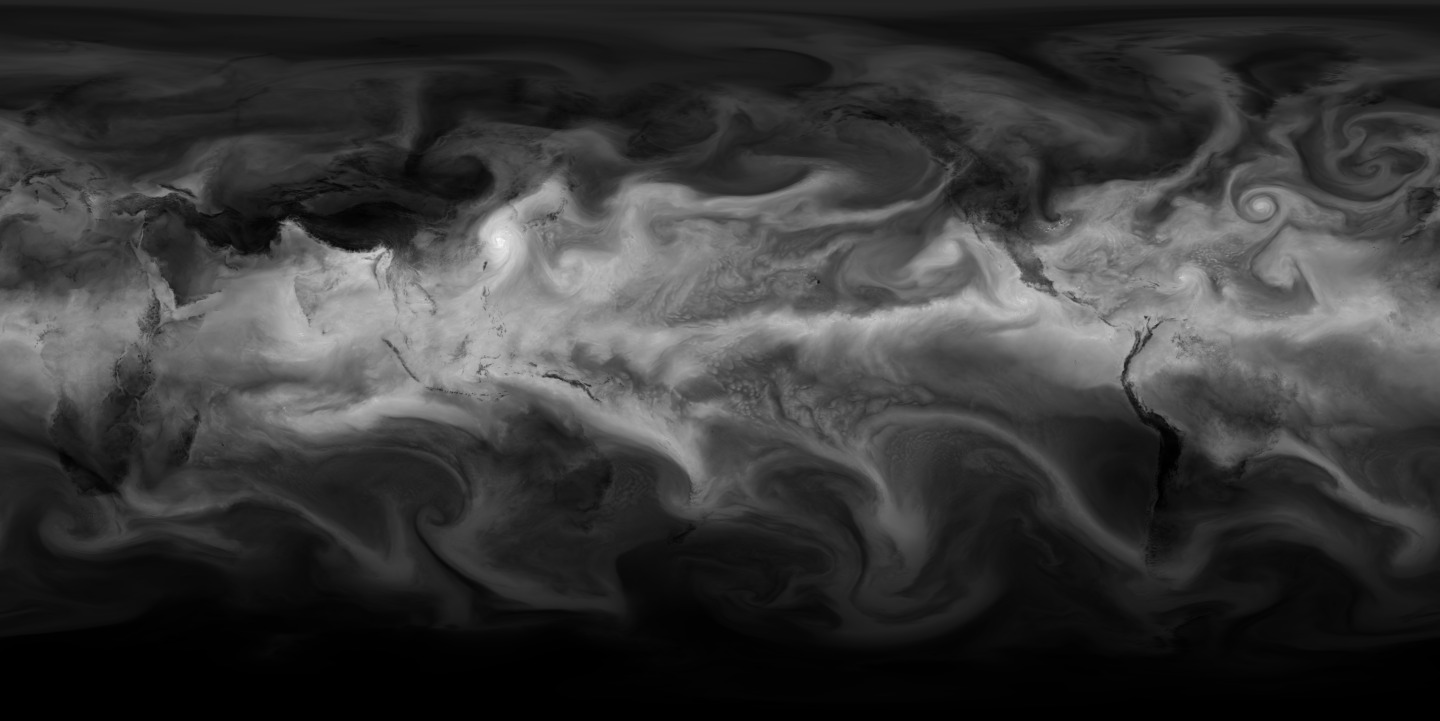

2022-09-05T06:00


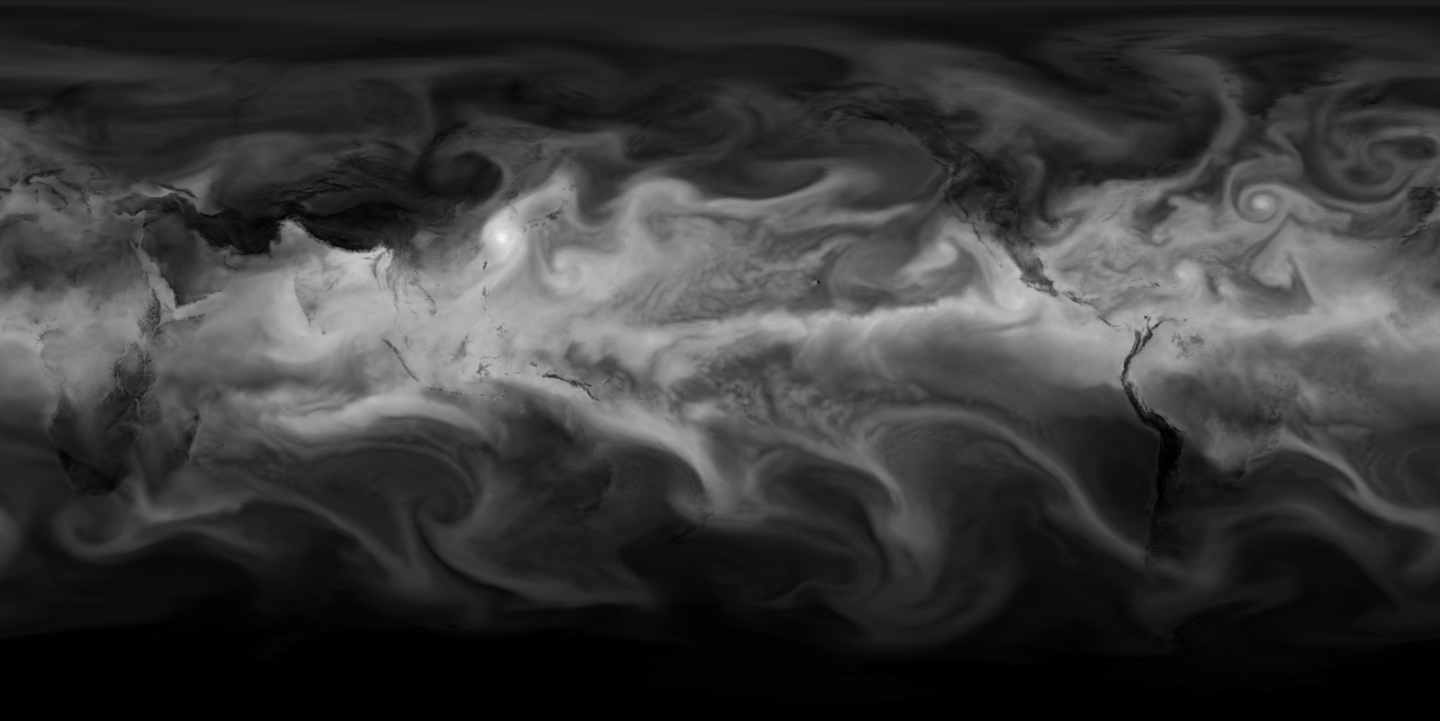

2022-09-05T12:00


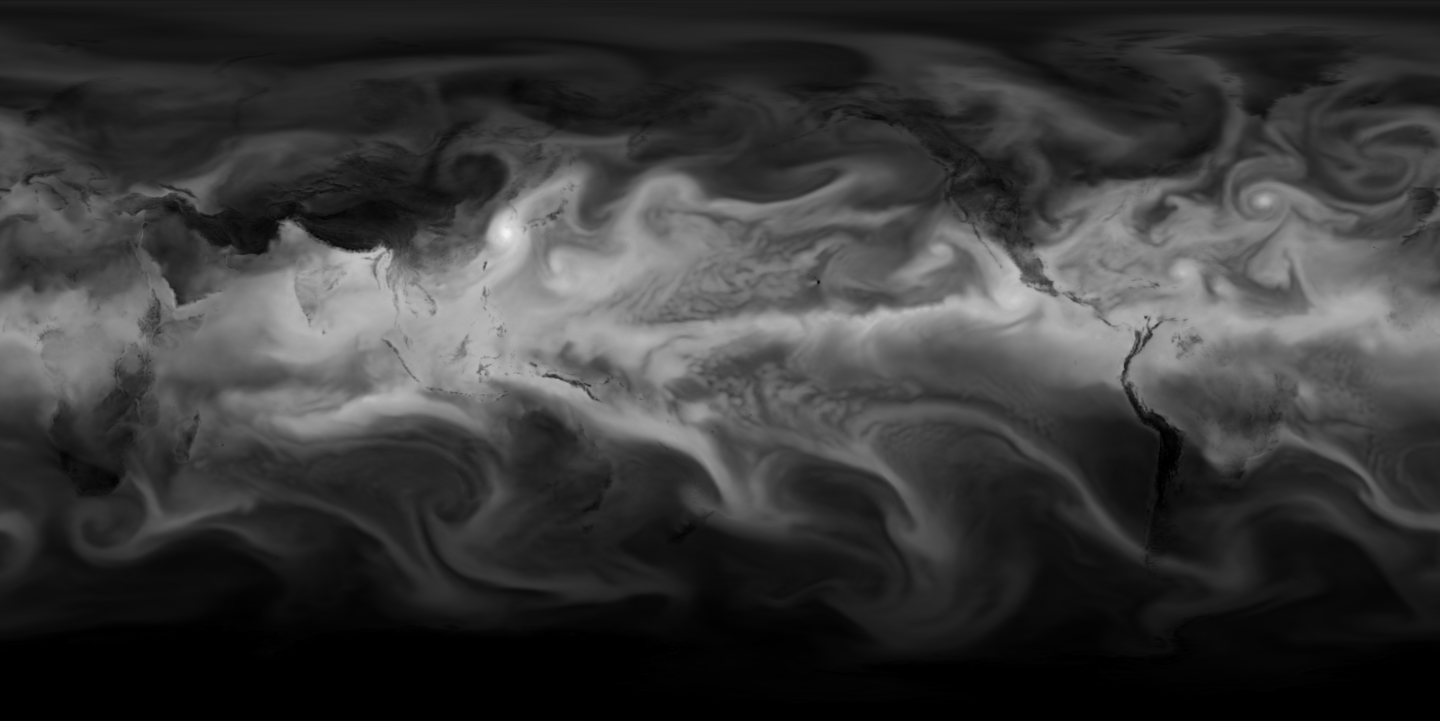

2022-09-05T18:00


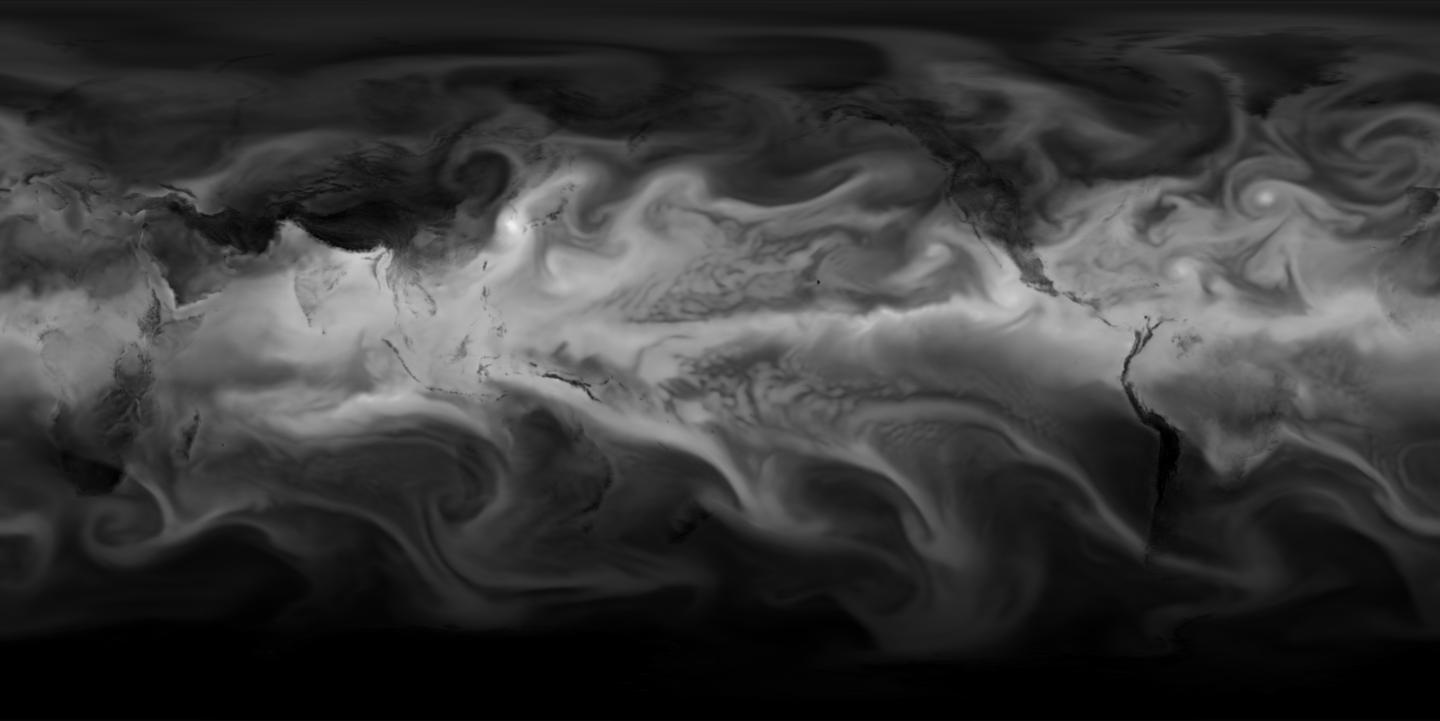

2022-09-06T00:00


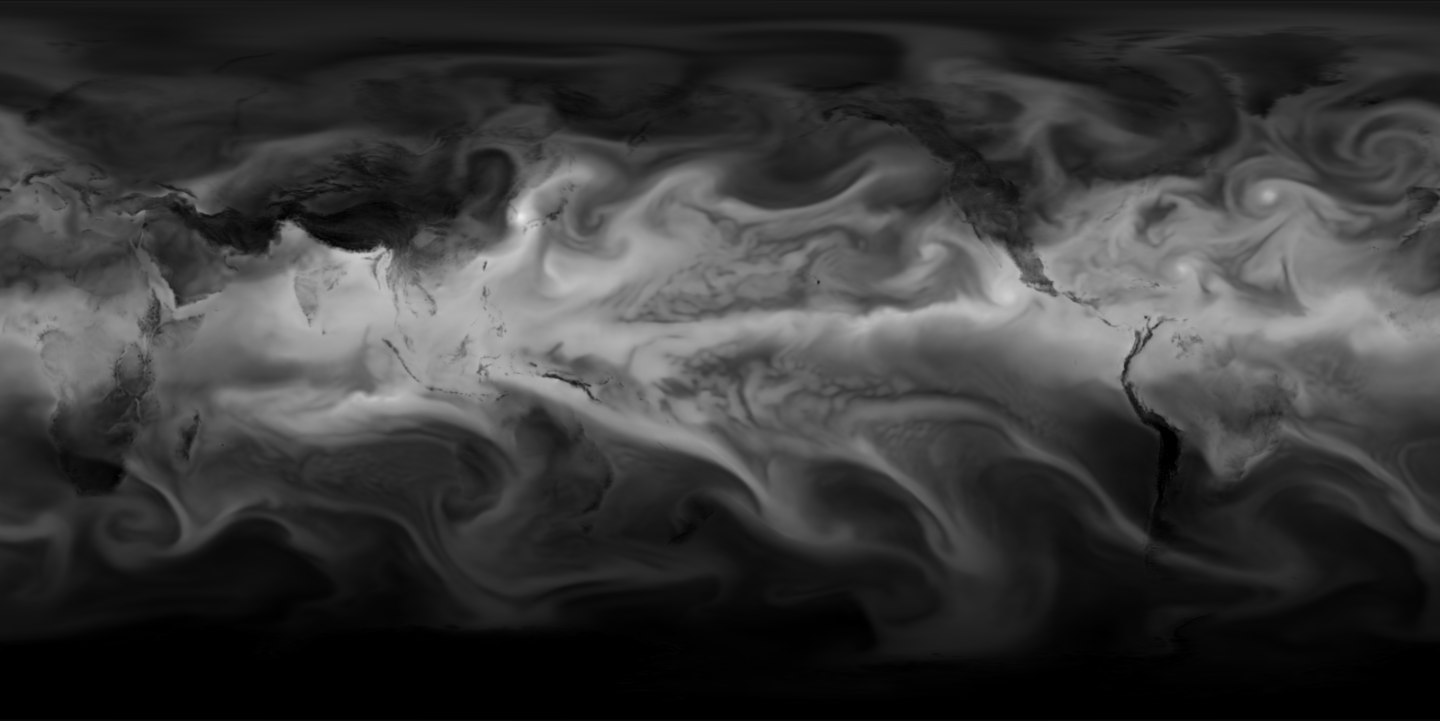

In [5]:
for message in results:
    images = texturefilelist_to_images(message)
    for texture_file, image in zip(message.texture_files, images):
        print(texture_file.timestamp)
        display(image)

## Customizing the forecast

Try changing the configuration in Step 1 and re-running Steps 1-3:

- **Longer lead time:** increase `n_steps` (e.g. `n_steps=20` for a ~5-day forecast). You will get more frames, and the run will take longer.
- **A different variable:** change `variable` to another field produced by SFNO, and adjust `min_value` / `max_value` in `ConvertToUint8` to a sensible range for that field (the render step normalizes values into 0-255 using this range).
- **A different initial date:** change `date` to another GFS analysis date.

You can also run the SFNO operation on a specific site in a distributed federation by passing `site=...` to the operations, exactly as shown for the Flare target in the [Basic Pipeline](01-basic-pipeline.ipynb) notebook.

## Step 4: Cleanup

Close the session to release resources. In local mode this stops the background threads, queues, and any child processes started for execution; leaving sessions open can leak these across repeated runs in a long-lived kernel.

In [ ]:
session.close()

## Recap

You just ran a full AI weather forecast through DFM: loading a global initial condition, unrolling an SFNO forecast on the GPU, and rendering the result — all as a single DFM pipeline. The same pattern applies to the other AI model adapters in `nv-dfm-lib-weather` (for example the cBottle operations), which plug into pipelines the same way.